# BÀI THỰC HÀNH 4: MẠNG NEURAL HỒI QUY

<b>Hướng dẫn nộp bài:</b> Các bạn commit và push code lên github, sử dụng file txt đặt tên theo cú pháp <MSSV>.txt chứa đường link dẫn đến github của bài thực hành và nộp file txt này tên courses.

Bộ dữ liệu sử dụng: [PhoMT](https://drive.google.com/drive/folders/186OAOuSEYEDVcry7WP5UBdqECXo26QAb?usp=drive_link).

In [1]:
import json
import random
import time
import unicodedata
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence
from torch.utils.data import DataLoader

random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(4)
device = torch.device('cpu')
config = dict(embedding=256, hidden=256, layers=3, dropout=0.3, batch=32,
              learning_rate=0.001, epochs=10, max_words=50, vocab_size=10000,
              min_freq=2, teacher_ratio=0.5)
print('Thiết bị:', device)
print(config)

Thiết bị: cpu
{'embedding': 256, 'hidden': 256, 'layers': 3, 'dropout': 0.3, 'batch': 32, 'learning_rate': 0.001, 'epochs': 10, 'max_words': 50, 'vocab_size': 10000, 'min_freq': 2, 'teacher_ratio': 0.5}


In [2]:
def tokenize(text):
    text = unicodedata.normalize('NFC', text.replace('\ufeff', ''))
    return text.lower().split()

data = {}
for split in ['train', 'dev', 'test']:
    with open(f'data/small-{split}.json', encoding='utf-8-sig') as f:
        rows = json.load(f)
    data[split] = []
    for row in rows:
        source = tokenize(row['english'])
        target = tokenize(row['vietnamese'])
        if 1 <= len(source) <= config['max_words'] and 1 <= len(target) <= config['max_words']:
            data[split].append({'src': source, 'tgt': target})
    print(split, 'gốc:', len(rows), 'sau lọc:', len(data[split]))

special = ['<pad>', '<unk>', '<bos>', '<eos>']

def make_vocab(rows, language):
    counts = Counter(word for row in rows for word in row[language])
    words = sorted(counts, key=lambda word: (-counts[word], word))
    words = [word for word in words if counts[word] >= config['min_freq'] and word not in special]
    return {word: i for i, word in enumerate(special + words[:config['vocab_size'] - 4])}

src_vocab = make_vocab(data['train'], 'src')
tgt_vocab = make_vocab(data['train'], 'tgt')
tgt_words = list(tgt_vocab)
print('Từ vựng:', len(src_vocab), len(tgt_vocab))

def collate(rows):
    src = [torch.tensor([src_vocab.get(w, 1) for w in row['src']] + [3]) for row in rows]
    tgt = [torch.tensor([2] + [tgt_vocab.get(w, 1) for w in row['tgt']] + [3]) for row in rows]
    return pad_sequence(src, batch_first=True), pad_sequence(tgt, batch_first=True), [row['tgt'] for row in rows]

def make_loader(rows, shuffle=False):
    generator = torch.Generator().manual_seed(42)
    return DataLoader(rows, batch_size=config['batch'], shuffle=shuffle,
                      collate_fn=collate, generator=generator)

train gốc: 20000 sau lọc: 18607
dev gốc: 2000 sau lọc: 1901
test gốc: 2000 sau lọc: 1786


Từ vựng: 8943 4003


In [3]:
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(len(src_vocab), 256, padding_idx=0)
        self.dropout = nn.Dropout(config['dropout'])
        self.lstm = nn.LSTM(256, 256, num_layers=3, batch_first=True, dropout=config['dropout'])

    def forward(self, src):
        lengths = src.ne(0).sum(dim=1).cpu()
        embedded = self.dropout(self.embedding(src))
        packed = pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        output, state = self.lstm(packed)
        output, _ = pad_packed_sequence(output, batch_first=True, total_length=src.size(1))
        return output, state

class Decoder(nn.Module):
    def __init__(self, attention):
        super().__init__()
        self.attention = attention
        self.embedding = nn.Embedding(len(tgt_vocab), 256, padding_idx=0)
        self.dropout = nn.Dropout(config['dropout'])
        width = 256 if attention == 'none' else 512
        self.lstm = nn.LSTM(width, 256, num_layers=3, batch_first=True, dropout=config['dropout'])
        if attention == 'bahdanau':
            self.attn_encoder = nn.Linear(256, 256, bias=False)
            self.attn_decoder = nn.Linear(256, 256, bias=False)
            self.attn_score = nn.Linear(256, 1, bias=False)
        elif attention == 'luong':
            self.attn_encoder = nn.Linear(256, 256, bias=False)
        if attention != 'none':
            self.combine = nn.Linear(512, 256)
        self.output = nn.Linear(256, len(tgt_vocab))

    def forward(self, token, state, memory, mask, feeding):
        embedded = self.dropout(self.embedding(token)).unsqueeze(1)
        weights = None
        if self.attention == 'bahdanau':
            scores = self.attn_score(torch.tanh(self.attn_encoder(memory) + self.attn_decoder(state[0][-1]).unsqueeze(1))).squeeze(-1)
            weights = torch.softmax(scores.masked_fill(~mask, float('-inf')), dim=1)
            context = torch.bmm(weights.unsqueeze(1), memory)
            embedded = torch.cat((embedded, context), dim=2)
        elif self.attention == 'luong':
            embedded = torch.cat((embedded, feeding.unsqueeze(1)), dim=2)
        output, state = self.lstm(embedded, state)
        if self.attention == 'luong':
            scores = torch.bmm(self.attn_encoder(memory), output.transpose(1, 2)).squeeze(-1)
            weights = torch.softmax(scores.masked_fill(~mask, float('-inf')), dim=1)
            context = torch.bmm(weights.unsqueeze(1), memory)
        if self.attention != 'none':
            output = torch.tanh(self.combine(torch.cat((output, context), dim=2)))
            feeding = output.squeeze(1)
        return self.output(self.dropout(output.squeeze(1))), state, feeding, weights

class Translator(nn.Module):
    def __init__(self, attention):
        super().__init__()
        self.encoder = Encoder()
        self.decoder = Decoder(attention)

    def forward(self, src, tgt, teacher_ratio):
        memory, state = self.encoder(src)
        mask = src.ne(0)
        feeding = memory.new_zeros(src.size(0), 256)
        token = tgt[:, 0]
        outputs = []
        for step in range(1, tgt.size(1)):
            output, state, feeding, _ = self.decoder(token, state, memory, mask, feeding)
            outputs.append(output)
            use_target = torch.rand(src.size(0), device=src.device) < teacher_ratio
            token = torch.where(use_target, tgt[:, step], output.argmax(dim=1).detach())
        return torch.stack(outputs, dim=1)

    def translate(self, src):
        memory, state = self.encoder(src)
        mask = src.ne(0)
        feeding = memory.new_zeros(src.size(0), 256)
        token = torch.full((src.size(0),), 2, dtype=torch.long, device=src.device)
        finished = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        result, attentions = [], []
        for _ in range(config['max_words'] + 1):
            output, state, feeding, weights = self.decoder(token, state, memory, mask, feeding)
            output[:, [0, 2]] = float('-inf')
            token = output.argmax(dim=1)
            token = torch.where(finished, torch.full_like(token, 3), token)
            result.append(token)
            if weights is not None:
                attentions.append(weights)
            finished |= token.eq(3)
            if finished.all():
                break
        return torch.stack(result, dim=1), torch.stack(attentions, dim=1) if attentions else None

In [4]:
criterion = nn.CrossEntropyLoss(ignore_index=0)
output_dir = Path('artifacts')
output_dir.mkdir(exist_ok=True)

def decode(ids):
    words = []
    for token in ids:
        if token == 3:
            break
        if token not in (0, 2):
            words.append(tgt_words[token])
    return words

def rouge_l(prediction, reference):
    previous = [0] * (len(reference) + 1)
    for word in prediction:
        current = [0]
        for j, ref in enumerate(reference, 1):
            current.append(previous[j - 1] + 1 if word == ref else max(previous[j], current[-1]))
        previous = current
    overlap = previous[-1]
    if not prediction or not reference or not overlap:
        return 0.0
    return 2 * overlap / (len(prediction) + len(reference))

def evaluate(model, rows):
    model.eval()
    scores = []
    with torch.no_grad():
        for src, _, references in make_loader(rows):
            predictions, _ = model.translate(src.to(device))
            for prediction, reference in zip(predictions.cpu().tolist(), references):
                scores.append(rouge_l(decode(prediction), reference))
    return sum(scores) / len(scores)

def train_model(attention):
    random.seed(42)
    torch.manual_seed(42)
    model = Translator(attention).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'])
    train_loader = make_loader(data['train'], shuffle=True)
    best_score = -1.0
    history = []
    checkpoint = output_dir / f'{attention}.pt'
    for epoch in range(1, config['epochs'] + 1):
        model.train()
        loss_total, tokens_total = 0.0, 0
        start = time.perf_counter()
        for src, tgt, _ in train_loader:
            src, tgt = src.to(device), tgt.to(device)
            optimizer.zero_grad()
            outputs = model(src, tgt, config['teacher_ratio'])
            target = tgt[:, 1:]
            loss = criterion(outputs.reshape(-1, outputs.size(-1)), target.reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            count = target.ne(0).sum().item()
            loss_total += loss.item() * count
            tokens_total += count
        seconds = time.perf_counter() - start
        dev_score = evaluate(model, data['dev'])
        history.append({'epoch': epoch, 'train_loss': loss_total / tokens_total,
                        'dev_rouge_l': dev_score, 'seconds': seconds})
        if dev_score > best_score:
            best_score = dev_score
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint)
        print(attention, 'epoch', epoch, 'train_loss', round(loss_total / tokens_total, 4),
              'dev_ROUGE-L', round(dev_score, 4), 'giây', round(seconds, 1), flush=True)
        (output_dir / f'{attention}_history.json').write_text(json.dumps(history, ensure_ascii=False, indent=2), encoding='utf-8')
    model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    return model, history, best_epoch

assert rouge_l(['tôi', 'yêu', 'bạn'], ['tôi', 'yêu', 'bạn']) == 1.0
assert rouge_l(['tôi'], ['bạn']) == 0.0
print('ROUGE-L: PASS')

ROUGE-L: PASS


#### Bài 1: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụng độ đo ROUGE-L.

In [5]:
models, histories, best_epochs = {}, {}, {}
models['none'], histories['none'], best_epochs['none'] = train_model('none')

none epoch 1 train_loss 6.0188 dev_ROUGE-L 0.1283 giây 464.1


none epoch 2 train_loss 5.7109 dev_ROUGE-L 0.1703 giây 523.0


none epoch 3 train_loss 5.5201 dev_ROUGE-L 0.1861 giây 513.4


none epoch 4 train_loss 5.3816 dev_ROUGE-L 0.1955 giây 517.1


none epoch 5 train_loss 5.2687 dev_ROUGE-L 0.205 giây 526.8


none epoch 6 train_loss 5.172 dev_ROUGE-L 0.2137 giây 515.8


none epoch 7 train_loss 5.0871 dev_ROUGE-L 0.2162 giây 546.8


none epoch 8 train_loss 5.0081 dev_ROUGE-L 0.2214 giây 548.2


none epoch 9 train_loss 4.9418 dev_ROUGE-L 0.2263 giây 493.6


none epoch 10 train_loss 4.884 dev_ROUGE-L 0.2291 giây 476.9


#### Bài 2: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Neural Machine Translation by Jointly Learning to Align and Translate](https://arxiv.org/abs/1409.0473)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

In [6]:
models['bahdanau'], histories['bahdanau'], best_epochs['bahdanau'] = train_model('bahdanau')

bahdanau epoch 1 train_loss 6.0423 dev_ROUGE-L 0.1376 giây 752.0


bahdanau epoch 2 train_loss 5.6597 dev_ROUGE-L 0.1919 giây 743.5


bahdanau epoch 3 train_loss 5.3658 dev_ROUGE-L 0.2163 giây 732.0


bahdanau epoch 4 train_loss 5.1606 dev_ROUGE-L 0.2381 giây 728.0


bahdanau epoch 5 train_loss 4.9956 dev_ROUGE-L 0.2468 giây 719.8


bahdanau epoch 6 train_loss 4.8601 dev_ROUGE-L 0.2686 giây 723.2


bahdanau epoch 7 train_loss 4.7453 dev_ROUGE-L 0.2703 giây 723.8


bahdanau epoch 8 train_loss 4.6415 dev_ROUGE-L 0.2815 giây 749.1


bahdanau epoch 9 train_loss 4.5544 dev_ROUGE-L 0.2955 giây 751.7


bahdanau epoch 10 train_loss 4.4719 dev_ROUGE-L 0.3008 giây 758.3


#### Bài 3: Xây dựng kiến trúc Encoder-Decoder gồm 3 lớp LSTM cho module encoder và 3 lớp LSTM cho module decoder, với hidden size là 256, cho bài toán dịch máy từ tiếng Anh sang tiếng Việt. Module decoder được trang bị kỹ thuật attention theo mô tả của nghiên cứu "[Effective Approaches to Attention-based Neural Machine Translation](https://arxiv.org/abs/1508.04025)". Huấn luyện mô hình này trên bộ dữ liệu PhoMT sử dụng Adam làm phương thức tối ưu tham số. Đánh giá độ hiệu quả của mô hình sử dụn độ đo ROUGE-L.

In [7]:
models['luong'], histories['luong'], best_epochs['luong'] = train_model('luong')

luong epoch 1 train_loss 6.0522 dev_ROUGE-L 0.1261 giây 715.9


luong epoch 2 train_loss 5.6761 dev_ROUGE-L 0.1902 giây 723.8


luong epoch 3 train_loss 5.3923 dev_ROUGE-L 0.2184 giây 785.1


luong epoch 4 train_loss 5.1933 dev_ROUGE-L 0.2393 giây 751.4


luong epoch 5 train_loss 5.0279 dev_ROUGE-L 0.2493 giây 736.1


luong epoch 6 train_loss 4.8928 dev_ROUGE-L 0.2682 giây 718.2


luong epoch 7 train_loss 4.7764 dev_ROUGE-L 0.2755 giây 707.1


luong epoch 8 train_loss 4.6753 dev_ROUGE-L 0.2816 giây 721.9


luong epoch 9 train_loss 4.5841 dev_ROUGE-L 0.2948 giây 708.6


luong epoch 10 train_loss 4.4999 dev_ROUGE-L 0.3 giây 724.9


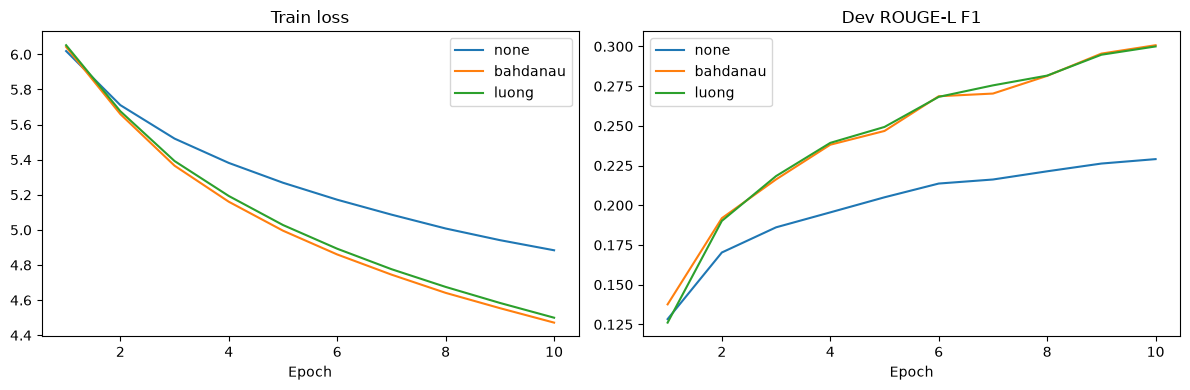

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, records in histories.items():
    axes[0].plot([r['epoch'] for r in records], [r['train_loss'] for r in records], label=name)
    axes[1].plot([r['epoch'] for r in records], [r['dev_rouge_l'] for r in records], label=name)
axes[0].set_title('Train loss')
axes[1].set_title('Dev ROUGE-L F1')
for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend()
fig.tight_layout()
fig.savefig(output_dir / 'learning_curves.png', dpi=150)
plt.show()

In [9]:
results = []
for name, model in models.items():
    test_score = evaluate(model, data['test'])
    history = histories[name]
    row = {'model': name, 'dev_rouge_l': history[best_epochs[name] - 1]['dev_rouge_l'],
           'test_rouge_l': test_score, 'best_epoch': best_epochs[name],
           'parameters': sum(p.numel() for p in model.parameters()),
           'seconds_per_epoch': sum(r['seconds'] for r in history) / len(history)}
    results.append(row)
    print(name, '| dev:', round(row['dev_rouge_l'], 4), '| test:', round(test_score, 4),
          '| epoch tốt nhất:', row['best_epoch'], '| tham số:', row['parameters'],
          '| giây/epoch:', round(row['seconds_per_epoch'], 1))
(output_dir / 'results.json').write_text(json.dumps(results, ensure_ascii=False, indent=2), encoding='utf-8')

none | dev: 0.2291 | test: 0.2345 | epoch tốt nhất: 10 | tham số: 7500963 | giây/epoch: 512.6


bahdanau | dev: 0.3008 | test: 0.3131 | epoch tốt nhất: 10 | tham số: 8025763 | giây/epoch: 738.1


luong | dev: 0.3 | test: 0.3156 | epoch tốt nhất: 10 | tham số: 7959971 | giây/epoch: 729.3


613

none - câu 1
Anh: do n't worry .
Việt gốc: đừng lo lắng .
Việt dịch: đừng không không .
ROUGE-L: 0.5
none - câu 2
Anh: birthmarks are n't exactly a rare phenomenon .
Việt gốc: vết bớt không phải là một hiện tượng hiếm có .
Việt dịch: <unk> <unk> không không là một một . .
ROUGE-L: 0.4
none - câu 3
Anh: the netherlands invented a record speed wifi router
Việt gốc: hà lan phát minh thiết bị phát wifi tốc độ nhanh kỷ lục
Việt dịch: chiếc máy của là là một một <unk> <unk>
ROUGE-L: 0.0
bahdanau - câu 1
Anh: do n't worry .
Việt gốc: đừng lo lắng .
Việt dịch: đừng lo lắng .
ROUGE-L: 1.0


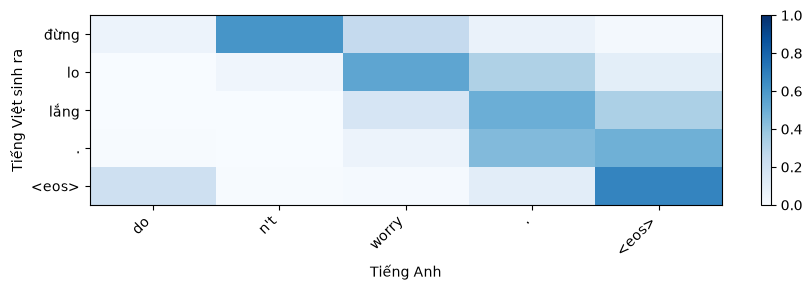

bahdanau - câu 2
Anh: birthmarks are n't exactly a rare phenomenon .
Việt gốc: vết bớt không phải là một hiện tượng hiếm có .
Việt dịch: những người không không là một ý tưởng .
ROUGE-L: 0.4


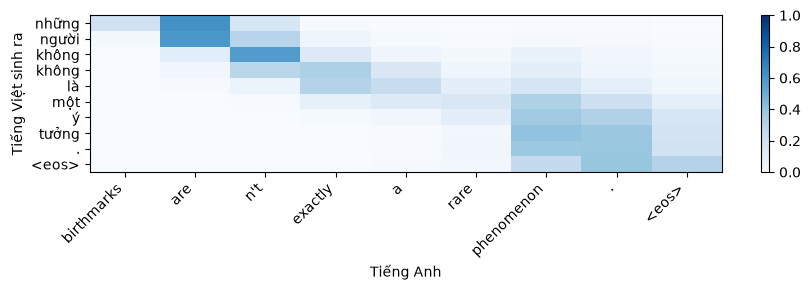

bahdanau - câu 3
Anh: the netherlands invented a record speed wifi router
Việt gốc: hà lan phát minh thiết bị phát wifi tốc độ nhanh kỷ lục
Việt dịch: các nhà của của một một <unk> <unk> .
ROUGE-L: 0.0


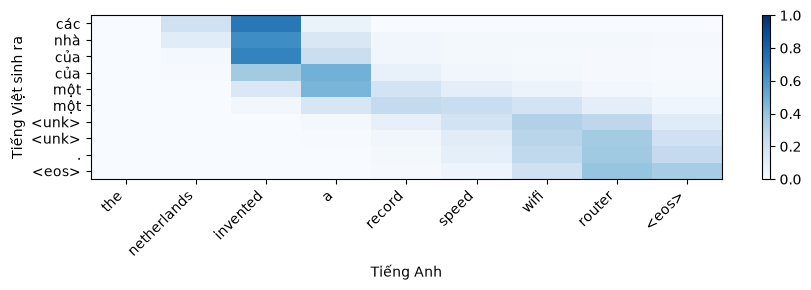

luong - câu 1
Anh: do n't worry .
Việt gốc: đừng lo lắng .
Việt dịch: đừng lo lắng .
ROUGE-L: 1.0
luong - câu 2
Anh: birthmarks are n't exactly a rare phenomenon .
Việt gốc: vết bớt không phải là một hiện tượng hiếm có .
Việt dịch: những <unk> không không phải là một quan trọng .
ROUGE-L: 0.4762
luong - câu 3
Anh: the netherlands invented a record speed wifi router
Việt gốc: hà lan phát minh thiết bị phát wifi tốc độ nhanh kỷ lục
Việt dịch: khu vực đã một một <unk> <unk> <unk> <unk>
ROUGE-L: 0.0


2171

In [10]:
examples = [data['test'][i] for i in [1712, 83, 155]]
example_results = []
for name, model in models.items():
    model.eval()
    for index, row in enumerate(examples, 1):
        src, _, _ = collate([row])
        with torch.no_grad():
            ids, weights = model.translate(src.to(device))
        predicted = decode(ids[0].cpu().tolist())
        score = rouge_l(predicted, row['tgt'])
        print(name, '- câu', index)
        print('Anh:', ' '.join(row['src']))
        print('Việt gốc:', ' '.join(row['tgt']))
        print('Việt dịch:', ' '.join(predicted))
        print('ROUGE-L:', round(score, 4))
        example_results.append({'model': name, 'sentence': index, 'source': ' '.join(row['src']),
                                'reference': ' '.join(row['tgt']), 'translation': ' '.join(predicted),
                                'rouge_l': score})
        if name == 'bahdanau':
            labels = predicted + ['<eos>'] if 3 in ids[0].tolist() else predicted
            matrix = weights[0, :len(labels), :len(row['src']) + 1].cpu().numpy()
            fig, ax = plt.subplots(figsize=(9, max(3, len(labels) * 0.3)))
            image = ax.imshow(matrix, aspect='auto', cmap='Blues', vmin=0, vmax=1)
            ax.set_xticks(range(len(row['src']) + 1), row['src'] + ['<eos>'], rotation=45, ha='right')
            ax.set_yticks(range(len(labels)), labels)
            ax.set_xlabel('Tiếng Anh')
            ax.set_ylabel('Tiếng Việt sinh ra')
            fig.colorbar(image, ax=ax)
            fig.tight_layout()
            fig.savefig(output_dir / f'bahdanau_attention_{index}.png', dpi=150)
            plt.show()
(output_dir / 'examples.json').write_text(json.dumps(example_results, ensure_ascii=False, indent=2), encoding='utf-8')